<a href="https://colab.research.google.com/github/pjacierda/busa3022-market-intelligence/blob/main/dashboard/dashboard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dashboard: ASX 200 market activity (Part 3)
BUSA3022 – Dashboard lead. Question this answers: *how has market activity trended over the past 90 days, and is there anything we should be watching?*

**Run order:** Runtime → Run all. Column names live in cell 1 so a rename is a one-line fix.

In [1]:
# 1. Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import HTML, display

DATA_URL = "https://raw.githubusercontent.com/pjacierda/busa3022-market-intelligence/main/data/clean/market_daily.csv"
CLOSE = "asx200_close"      # column names live here: if the pipeline renames a column, change it once

In [2]:
# 2. Load the team's clean data (falls back to a manual upload if the repo link fails)
try:
    df = pd.read_csv(DATA_URL, parse_dates=["date"])
except Exception as e:
    print("Could not load from GitHub:", e)
    from google.colab import files
    uploaded = files.upload()      # pick market_daily.csv from your computer
    df = pd.read_csv(next(iter(uploaded)), parse_dates=["date"])

df = df.sort_values("date").reset_index(drop=True)
print(df.shape)
df.tail()

Could not load from GitHub: HTTP Error 404: Not Found


Saving market_daily (1).csv to market_daily (1).csv
(377, 5)


,date,asx200_close,asx200_volume,bond10y_yield,bond10y_missing
372,2026-10-19,8845.700195,826900,5.283,True
373,2026-10-20,8816.900391,798300,5.283,True
374,2026-10-21,8831.299805,919200,5.283,True
375,2026-10-22,8793.200195,814800,5.283,True
376,2026-10-23,8795.200195,0,5.283,True


In [3]:
# 3. Basic checks (these results are good material for the data quality section)
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Duplicate dates:", df["date"].duplicated().sum())
print("Missing closes:", df[CLOSE].isna().sum())
print("Zero-volume days:", (df["asx200_volume"] == 0).sum())

# The newest day is treated as provisional if its volume is 0 (figures not final yet)
latest = df.iloc[-1]
provisional = latest["asx200_volume"] == 0
print("Latest day:", latest["date"].date(), "| provisional?", provisional)

Date range: 2025-05-05 to 2026-10-23
Duplicate dates: 0
Missing closes: 0
Zero-volume days: 2
Latest day: 2026-10-23 | provisional? True


In [4]:
# 4. Metrics
df["rolling_avg_20d"] = df[CLOSE].rolling(window=20).mean()               # 20-day average of the close
df["daily_return_pct"] = df[CLOSE].pct_change() * 100                     # % change vs previous trading day
df["volatility_14d"] = df["daily_return_pct"].rolling(window=14).std()    # how much daily moves have been swinging
df["close_vs_avg_pct"] = (df[CLOSE] / df["rolling_avg_20d"] - 1) * 100    # how far today's close sits from its average

# Hand check on one row: recompute it the long way and compare
i = 100
print("20-day avg matches:", np.isclose(df[CLOSE].iloc[i-19:i+1].mean(), df["rolling_avg_20d"].iloc[i]))
print("Daily return matches:", np.isclose((df[CLOSE].iloc[i] / df[CLOSE].iloc[i-1] - 1) * 100, df["daily_return_pct"].iloc[i]))
print("14-day volatility matches:", np.isclose(df["daily_return_pct"].iloc[i-13:i+1].std(), df["volatility_14d"].iloc[i]))

# The first rows have no value yet (not enough history) - they stay empty, not zero
print("First row with a 20-day average:", df["rolling_avg_20d"].first_valid_index())
print("First row with a 14-day volatility:", df["volatility_14d"].first_valid_index())

20-day avg matches: True
Daily return matches: True
14-day volatility matches: True
First row with a 20-day average: 19
First row with a 14-day volatility: 14


In [5]:
# 5. RAG rule: compare the latest volatility with the past year
data = df.iloc[:-1].copy() if provisional else df.copy()     # leave out an unfinished latest day
year = data["volatility_14d"].dropna().tail(252)             # about one year of trading days
p50, p80 = year.quantile(0.50), year.quantile(0.80)

def rag(v):
    if v < p50:  return "GREEN"
    if v <= p80: return "AMBER"
    return "RED"

latest_vol = data["volatility_14d"].iloc[-1]
latest_pct = (year < latest_vol).mean() * 100                # "higher than X% of days this year"
status = rag(latest_vol)
print(f"50th percentile: {p50:.2f} | 80th percentile: {p80:.2f} | latest: {latest_vol:.2f}")
print(f"Status: {status} (volatility higher than {latest_pct:.0f}% of days this year)")

50th percentile: 0.69 | 80th percentile: 0.99 | latest: 0.54
Status: GREEN (volatility higher than 25% of days this year)


In [6]:
# 6. The RAG signal box and the summary numbers
messages = {
    "GREEN": "Calm: the market has been steadier than on most days this year.",
    "AMBER": "Choppier than usual: worth keeping an eye on.",
    "RED":   "Unusually jumpy: more volatile than on about 80% of days this year. Worth watching closely.",
}
colours = {"GREEN": "#2e7d32", "AMBER": "#b26a00", "RED": "#c62828"}
display(HTML(f'<div style="padding:16px;border-radius:8px;background:{colours[status]};color:white;width:460px">'
             f'<div style="font-size:24px;font-weight:bold">{status}</div>'
             f'<div style="font-size:15px;margin-top:6px">{messages[status]}</div></div>'))

print(f"Latest close ({data['date'].iloc[-1].date()}): {data[CLOSE].iloc[-1]:,.0f}")
print(f"Versus its 20-day average: {data['close_vs_avg_pct'].iloc[-1]:+.1f}%")
print(f"14-day volatility: higher than {latest_pct:.0f}% of days this year")

Latest close (2026-10-22): 8,793
Versus its 20-day average: +0.6%
14-day volatility: higher than 25% of days this year


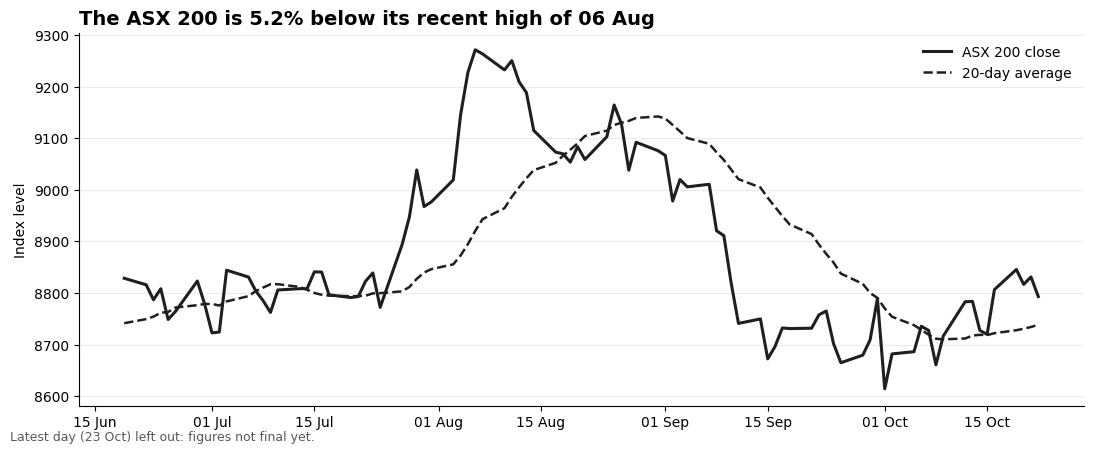

In [7]:
# 7. Price chart: 90 trading days with the 20-day average
last90 = data.tail(90)
from_peak = (last90[CLOSE].iloc[-1] / last90[CLOSE].max() - 1) * 100
peak_date = last90.loc[last90[CLOSE].idxmax(), "date"]
if from_peak > -0.5:
    headline = "The ASX 200 is at its 90-day high"
else:
    headline = f"The ASX 200 is {abs(from_peak):.1f}% below its recent high of {peak_date:%d %b}"

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(last90["date"], last90[CLOSE], color="#1f1f1f", lw=2.2, label="ASX 200 close")
ax.plot(last90["date"], last90["rolling_avg_20d"], color="#1f1f1f", lw=1.8, ls="--", label="20-day average")
ax.set_title(headline, loc="left", fontsize=14, fontweight="bold")
ax.set_ylabel("Index level")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
if provisional:
    fig.text(0.01, 0.01, f"Latest day ({latest['date']:%d %b}) left out: figures not final yet.", fontsize=9, color="#595959")
fig.tight_layout()
fig.savefig("price_chart.png", dpi=150, bbox_inches="tight")
plt.show()

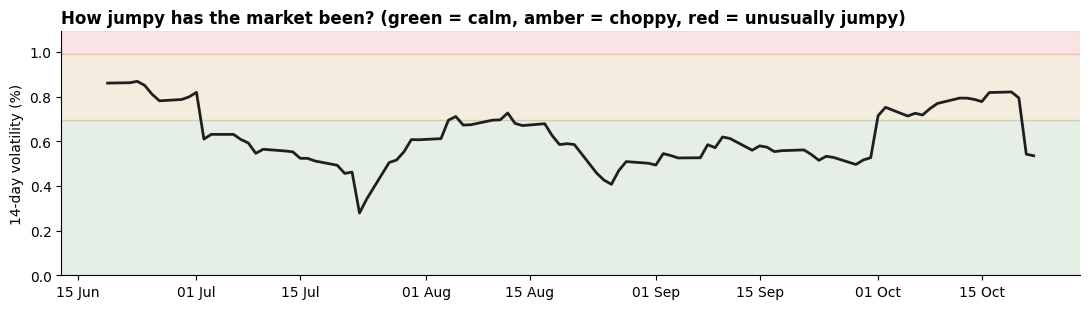

In [8]:
# 8. Volatility chart with the RAG bands (shows WHY the signal has its colour)
top = max(last90["volatility_14d"].max(), p80) * 1.1
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.axhspan(0, p50, color="#2e7d32", alpha=0.12)
ax.axhspan(p50, p80, color="#b26a00", alpha=0.12)
ax.axhspan(p80, top, color="#c62828", alpha=0.12)
ax.plot(last90["date"], last90["volatility_14d"], color="#1f1f1f", lw=2)
ax.set_ylim(0, top)
ax.set_title("How jumpy has the market been? (green = calm, amber = choppy, red = unusually jumpy)", loc="left", fontsize=12, fontweight="bold")
ax.set_ylabel("14-day volatility (%)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("volatility_chart.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# 9. Does the rule behave sensibly? Check the biggest one-day falls of the past year.
# (Note: the overall Green/Amber/Red split will be about 50/30/20 by construction, so it proves nothing on its own.)
yr = data.tail(252)
worst = yr.nsmallest(5, "daily_return_pct")[["date", "daily_return_pct", "volatility_14d"]].copy()
worst["status"] = worst["volatility_14d"].apply(rag)
worst

,date,daily_return_pct,volatility_14d,status
215,2026-03-09,-2.847136,1.114267,RED
194,2026-02-06,-2.029433,0.871156,AMBER
360,2026-10-01,-1.989913,0.714702,AMBER
212,2026-03-04,-1.940000,0.880387,AMBER
140,2025-11-18,-1.937159,0.689021,GREEN


## Still to add
- Bond yield panel and the 'moving together or diverging' note, once the group decides the macro series (the current yield file only has month-end values).
- Write the metric definitions in your own words in `docs/metric_definitions.md` before submitting.